# Task 1 – Concepts, Splits and Leakage

Run all cells from top to bottom. This notebook includes its own imports, synthetic dataset, and train/validation/test split setup.

# Week 2 – Weekly Assessment: Machine Learning
**YOHO Technologies | Loan Applicants Scenario**

This notebook completes Tasks 1–4 using one reproducible synthetic bank-loan dataset. Run cells from top to bottom. The test set is kept aside until the final evaluation in Task 4.

In [1]:
import warnings, os, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 0. Dataset Generation – Bank Loan Applicants

In [2]:
n_samples = 2000
rng = np.random.default_rng(RANDOM_STATE)

applicant_ids = np.arange(1001, 1001 + n_samples)
dates = pd.date_range("2024-01-01", periods=n_samples, freq="4h")
age = rng.integers(21, 66, n_samples)
annual_income = rng.lognormal(mean=10.8, sigma=0.6, size=n_samples)
loan_amount = np.clip(annual_income * rng.uniform(0.15, 0.65, n_samples) + rng.normal(0, 5000, n_samples), 5000, 150000)
credit_score = np.clip(rng.normal(670, 60, n_samples), 300, 850)
debt_to_income = np.clip((loan_amount * 0.12) / annual_income + rng.normal(0.15, 0.05, n_samples), 0.01, 0.95)
education = rng.choice(["High School", "Bachelor", "Master", "PhD"], n_samples, p=[0.30, 0.45, 0.20, 0.05])
employment = rng.choice(["Salaried", "Self-Employed", "Business", "Unemployed"], n_samples, p=[0.55, 0.25, 0.15, 0.05])
property_area = rng.choice(["Urban", "Semiurban", "Rural"], n_samples, p=[0.40, 0.35, 0.25])

# A synthetic probability of default, used only to create a realistic target.
logit = (-2.2 + 3.0 * debt_to_income - 0.006 * (credit_score - 650)
         + 0.45 * (employment == "Unemployed")
         + 0.25 * (employment == "Self-Employed")
         + 0.18 * (education == "High School"))
prob_default = 1 / (1 + np.exp(-logit))
default = rng.binomial(1, prob_default)

df = pd.DataFrame({
    "Applicant_ID": applicant_ids,
    "Application_Date": dates,
    "Age": age,
    "Annual_Income": annual_income,
    "Loan_Amount": loan_amount,
    "Credit_Score": credit_score,
    "Debt_to_Income": debt_to_income,
    "Education_Level": education,
    "Employment_Type": employment,
    "Property_Area": property_area,
    "Default": default
})

# Add missing values to demonstrate imputation.
for col in ["Annual_Income", "Credit_Score", "Employment_Type"]:
    missing_idx = rng.choice(df.index, size=int(0.03 * n_samples), replace=False)
    df.loc[missing_idx, col] = np.nan

print("Dataset shape:", df.shape)
print("Default rate:", round(df["Default"].mean(), 3))
display(df.head())

Dataset shape: (2000, 11)
Default rate: 0.18


,Applicant_ID,Application_Date,Age,Annual_Income,Loan_Amount,Credit_Score,Debt_to_Income,Education_Level,Employment_Type,Property_Area,Default
0,1001,2024-01-01 00:00:00,25,31403.817584,21781.751722,572.221835,0.286323,PhD,Salaried,Rural,0
1,1002,2024-01-01 04:00:00,55,85358.443759,39681.941286,619.451077,0.197838,Bachelor,Salaried,Urban,0
2,1003,2024-01-01 08:00:00,50,50049.466458,5000.000000,655.786146,0.190497,Bachelor,Salaried,Rural,0
3,1004,2024-01-01 12:00:00,40,41370.467114,9761.351215,644.974706,0.205203,Bachelor,Salaried,Urban,0
4,1005,2024-01-01 16:00:00,40,45995.131901,22921.204864,650.034598,0.199029,Bachelor,Salaried,Urban,0


## Shared feature engineering and train/validation/test split

In [3]:
def add_features(data):
    data = data.copy()
    dates = pd.to_datetime(data["Application_Date"])
    data["Application_Month"] = dates.dt.month
    data["Application_Day"] = dates.dt.day
    data["Income_to_Loan"] = data["Annual_Income"] / data["Loan_Amount"].replace(0, np.nan)
    data["Log_Annual_Income"] = np.log1p(data["Annual_Income"].clip(lower=0))
    return data

df_features = add_features(df)
target = "Default"
drop_cols = ["Applicant_ID", "Application_Date", target]
X = df_features.drop(columns=drop_cols)
y = df_features[target].astype(int)

# First split: 60% train+validation, 40% test; then split remaining into 60/20 overall.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_val
)
print(f"Train: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(X):.0%})")
print(f"Test: {len(X_test)} ({len(X_test)/len(X):.0%}) — kept aside until Task 4")

Train: 1200 (60%)
Validation: 400 (20%)
Test: 400 (20%) — kept aside until Task 4


In [4]:
# Shared column lists used by all task notebooks.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()


## Task 1 – Concepts, Splits and Leakage

Depth    1: train 0.819 | validation 0.820
Depth    3: train 0.827 | validation 0.820
Depth    5: train 0.853 | validation 0.815
Depth   10: train 0.929 | validation 0.770
Depth None: train 1.000 | validation 0.715


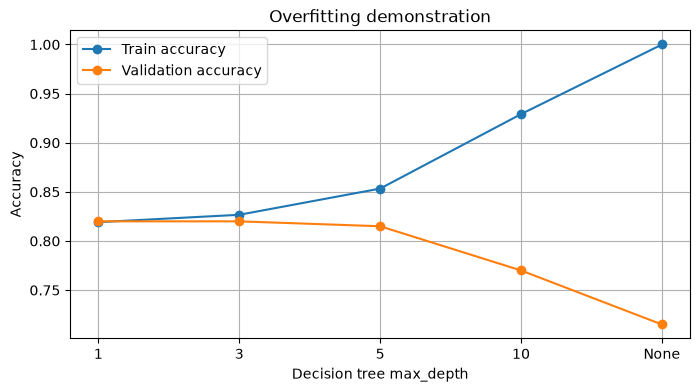

In [5]:
# Overfitting demonstration: median-impute numeric data, then compare tree depths.
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
tree_imputer = SimpleImputer(strategy="median")
Xtr_tree = tree_imputer.fit_transform(X_train[numeric_cols])
Xva_tree = tree_imputer.transform(X_val[numeric_cols])

depths = [1, 3, 5, 10, None]
train_scores, val_scores = [], []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(Xtr_tree, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(Xtr_tree)))
    val_scores.append(accuracy_score(y_val, model.predict(Xva_tree)))
    print(f"Depth {str(depth):>4}: train {train_scores[-1]:.3f} | validation {val_scores[-1]:.3f}")

plt.figure(figsize=(8, 4))
labels = [str(d) for d in depths]
plt.plot(labels, train_scores, marker="o", label="Train accuracy")
plt.plot(labels, val_scores, marker="o", label="Validation accuracy")
plt.xlabel("Decision tree max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting demonstration")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# 5-fold cross-validation for Logistic Regression (preprocessing is fitted inside pipeline).
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

def make_onehot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

cv_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", make_onehot())]), categorical_features)
])
logreg_cv = Pipeline([
    ("preprocessor", cv_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(logreg_cv, X_train_val, y_train_val, cv=cv, scoring="accuracy")
print(f"Logistic Regression 5-fold CV accuracy: {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")

Logistic Regression 5-fold CV accuracy: 0.821 +/- 0.001


In [7]:
# Leakage demonstration: scaling before splitting (incorrect) vs train-only fitting (correct).
leak_demo = X_train_val[numeric_features].copy()
leak_imputer = SimpleImputer(strategy="median")
leak_scaled_all = StandardScaler().fit_transform(leak_imputer.fit_transform(leak_demo))  # illustrative leakage
print("Incorrect approach: imputer/scaler see all rows before splitting.")
proper_imputer = SimpleImputer(strategy="median")
proper_scaler = StandardScaler()
train_imp = proper_imputer.fit_transform(X_train[numeric_features])
val_imp = proper_imputer.transform(X_val[numeric_features])
train_scaled = proper_scaler.fit_transform(train_imp)
val_scaled = proper_scaler.transform(val_imp)
print("Correct approach: fit imputer/scaler on training rows only; transform validation/test.")

Incorrect approach: imputer/scaler see all rows before splitting.
Correct approach: fit imputer/scaler on training rows only; transform validation/test.


**Data leakage explanation (4 lines)**

1. Data leakage happens when information from validation or test data enters model training.
2. Fitting an imputer or scaler before splitting lets it learn statistics from held-out rows.
3. This can make validation results look better than real-world performance.
4. Fit preprocessing only on training data, then use `transform` on validation and test data.

**Problem classification**
- Spam detection: supervised classification (labelled spam/not-spam examples).
- Customer segmentation: unsupervised clustering (no target label required).
- House price prediction: supervised regression (known sale prices).
- Anomaly detection: commonly unsupervised/semi-supervised (identify unusual patterns).

**7-step ML workflow:** define the problem; collect data; explore/clean data; engineer and preprocess features; split data; train and tune models; evaluate and deploy/monitor.